In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

print("Libraries imported successfully!")

Libraries imported successfully!


The previous cell failed because the file `cars(1).csv` was not found. Please upload the file using the cell below.

In [ ]:
from google.colab import files

print('Please upload the `cars(1).csv` file.')
uploaded = files.upload()

Please upload the `cars(1).csv` file.


Saving cars.csv to cars.csv


The `cars.csv` file has been uploaded successfully. Now, let's load the dataset into a pandas DataFrame.

In [ ]:
df = pd.read_csv('cars.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (38531, 30)


,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38531 entries, 0 to 38530
Data columns (total 30 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   manufacturer_name  38531 non-null  object 
 1   model_name         38531 non-null  object 
 2   transmission       38531 non-null  object 
 3   color              38531 non-null  object 
 4   odometer_value     38531 non-null  int64  
 5   year_produced      38531 non-null  int64  
 6   engine_fuel        38531 non-null  object 
 7   engine_has_gas     38531 non-null  bool   
 8   engine_type        38531 non-null  object 
 9   engine_capacity    38521 non-null  float64
 10  body_type          38531 non-null  object 
 11  has_warranty       38531 non-null  bool   
 12  state              38531 non-null  object 
 13  drivetrain         38531 non-null  object 
 14  price_usd          38531 non-null  float64
 15  is_exchangeable    38531 non-null  bool   
 16  location_region    385

In [ ]:
df.describe()

,odometer_value,year_produced,engine_capacity,price_usd,number_of_photos,up_counter,duration_listed
count,38531.000000,38531.000000,38521.000000,38531.000000,38531.000000,38531.000000,38531.000000
mean,248864.638447,2002.943734,2.055161,6639.971021,9.649062,16.306091,80.577249
std,136072.376530,8.065731,0.671178,6428.152018,6.093217,43.286933,112.826569
min,0.000000,1942.000000,0.200000,1.000000,1.000000,1.000000,0.000000
25%,158000.000000,1998.000000,1.600000,2100.000000,5.000000,2.000000,23.000000
50%,250000.000000,2003.000000,2.000000,4800.000000,8.000000,5.000000,59.000000
75%,325000.000000,2009.000000,2.300000,8990.000000,12.000000,16.000000,91.000000
max,1000000.000000,2019.000000,8.000000,50000.000000,86.000000,1861.000000,2232.000000


In [ ]:
print("Column Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['manufacturer_name', 'model_name', 'transmission', 'color', 'odometer_value', 'year_produced', 'engine_fuel', 'engine_has_gas', 'engine_type', 'engine_capacity', 'body_type', 'has_warranty', 'state', 'drivetrain', 'price_usd', 'is_exchangeable', 'location_region', 'number_of_photos', 'up_counter', 'feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'duration_listed']

Data Types:
manufacturer_name     object
model_name            object
transmission          object
color                 object
odometer_value         int64
year_produced          int64
engine_fuel           object
engine_has_gas          bool
engine_type           object
engine_capacity      float64
body_type             object
has_warranty            bool
state                 object
drivetrain            object
price_usd            float64
is_exchangeable         bool
location_region       object
number_of_photos       int64
up

In [ ]:
# Dependent variable (Y)
y = df['duration_listed']

# Independent variables (X)
X = df[
    [
        'odometer_value',
        'year_produced',
        'engine_capacity',
        'price_usd',
        'number_of_photos',
        'up_counter'
    ]
]

print("Independent variables:")
print(X.columns.tolist())

print("\nDependent variable:")
print(y.name)

Independent variables:
['odometer_value', 'year_produced', 'engine_capacity', 'price_usd', 'number_of_photos', 'up_counter']

Dependent variable:
duration_listed


In [ ]:
# Combine X and y
data = pd.concat([X, y], axis=1)

# Remove missing values
data = data.dropna()

# Separate X and y again
X = data[
    [
        'odometer_value',
        'year_produced',
        'engine_capacity',
        'price_usd',
        'number_of_photos',
        'up_counter'
    ]
]

y = data['duration_listed']

print("Data after removing missing values:")
print("X shape:", X.shape)
print("y shape:", y.shape)

Data after removing missing values:
X shape: (38521, 6)
y shape: (38521,)


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (30816, 6)
Testing data: (7705, 6)


In [ ]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# print("Multiple Linear Regression model trained successfully!")

LinearRegression()

In [ ]:
print("Intercept:", model.intercept_)

print("\nCoefficients:")

for column, coefficient in zip(X.columns, model.coef_):
    print(column, ":", coefficient)

Intercept: 513.3658125616564

Coefficients:
odometer_value : 3.4362813815389846e-06
year_produced : -0.22921157841950776
engine_capacity : 3.8206018692876533
price_usd : 0.00044918826617337815
number_of_photos : -1.5352797843273434
up_counter : 1.7882251586522806


In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[ 60.69708231  64.01174843  74.40362451  62.81006561  60.47330144
  55.17290584  89.41055691  66.76007419 234.50112407  59.9221328 ]


In [ ]:
r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred)

print("Model Performance")
print("-------------------------")
print("R² Score:", r2)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)

Model Performance
-------------------------
R² Score: 0.4855366026639496
Mean Squared Error: 7119.8716090854405
Root Mean Squared Error: 84.37933164635426
Mean Absolute Error: 48.04733363868195


In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print(comparison.head(20))

       Actual   Predicted
28609      70   60.697082
11031      43   64.011748
34077      22   74.403625
16666      63   62.810066
13128      42   60.473301
11751      92   55.172906
27922      45   89.410557
28423      21   66.760074
33089     764  234.501124
31363     125   59.922133
6803       31   58.931705
31309      84   58.104660
22336      19   61.461579
37035      30   46.011628
35374     144   86.965024
10358       7   58.083057
22313      18   59.461716
6747       42   50.361228
31796      19   63.360142
12149       5   49.884797


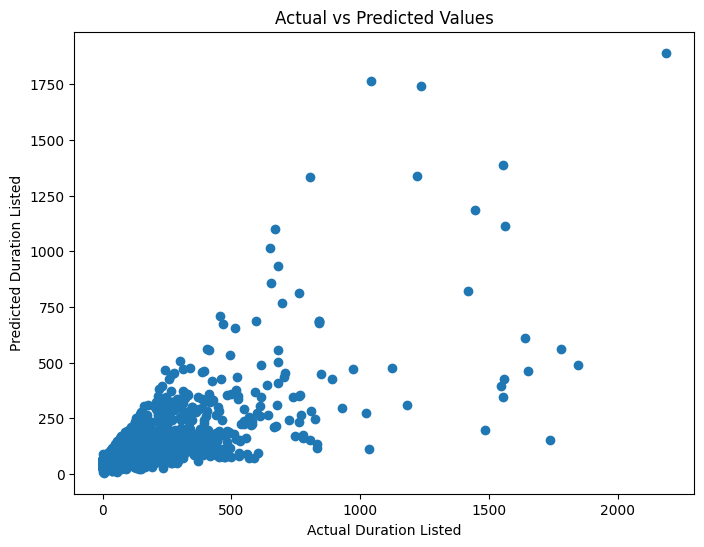

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Duration Listed")
plt.ylabel("Predicted Duration Listed")
plt.title("Actual vs Predicted Values")

plt.show()

In [ ]:
# Predictions for training and testing data
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# R² Score
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R²:", train_r2)
print("Testing R²:", test_r2)

# RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

Training R²: 0.49749394055007634
Testing R²: 0.4855366026639496
Training RMSE: 79.11225648212451
Testing RMSE: 84.37933164635426
